In [4]:
import os

# Define the directory path containing YOLO bounding box annotations
path = "../data/train/labels"

# Retrieve all items in the directory
labels = os.listdir(path)

# Filter the list to retain strictly .txt annotation files.
# This list comprehension prevents pipeline crashes caused by hidden OS files (e.g., .DS_Store) or system cache.
txt_files = [label for label in labels if label.endswith(".txt")]
txt_files

['005980b3a5f93085_jpg.rf.2QZCXGReqcBORWQJKQfO.txt',
 '005980b3a5f93085_jpg.rf.68f1ed44dbca53b707a1d3d82d4b7d9a.txt',
 '00aaf0a0a9ee7e71_jpg.rf.808b1e59067887493dffad63561c2a9d.txt',
 '00aaf0a0a9ee7e71_jpg.rf.KBCzX2HtZviBuQY9JDTQ.txt',
 '00e0422e47cdbeb7_jpg.rf.a8b6f2ef17a14eb8b9228d26366a124d.txt',
 '00e0422e47cdbeb7_jpg.rf.yHmAn1jB2oy8XzzQPBzc.txt',
 '00e13aca7d2f904a_jpg.rf.52342966f5a37167f8cfd7ea3f4dacef.txt',
 '00e13aca7d2f904a_jpg.rf.eQwpgo07vRFeI7SgvXy6.txt',
 '00e2d9121adc0c20_jpg.rf.50fa25618ccc9f0ebf59f2ffe64cf298.txt',
 '00e2d9121adc0c20_jpg.rf.rPP5CqB9mOv9wnRTTKR3.txt',
 '011a8a0a921c2376_jpg.rf.064272f1b667f68b4340d240244ff7e8.txt',
 '011a8a0a921c2376_jpg.rf.tflPpvQDTaDj9gH1xuDJ.txt',
 '0133391d627e6df4_jpg.rf.5fb6cc71948fdee8e2e7cbc9bbc5aeb1.txt',
 '0133391d627e6df4_jpg.rf.xszyOWdyIGCiI2HmiGNr.txt',
 '013476982d77e380_jpg.rf.3abcf2c4c484148e9e88d3c8c99bc236.txt',
 '013476982d77e380_jpg.rf.E6oudaF78aSJULyWaSIS.txt',
 '0158307c4ad94b38_jpg.rf.6VgRLvEWkhSwfdBdY9Fi.txt',
 '0

In [5]:
# Audit the dataset to analyze class distribution and check for potential class imbalances
class_counts = {}

for filename in labels:
    file_path = os.path.join(path, filename)
    with open(file_path, 'r') as file:
        contents = file.readlines()

    # Parse YOLO annotation format: <class_id> <x_center> <y_center> <width> <height>
    for content in contents:
        class_id = int(content.split()[0])
        # Aggregate counts per class ID
        class_counts[class_id] = class_counts.get(class_id, 0) + 1

total_objects = sum(class_counts.values())

print(f"Total annotated objects: {total_objects}")
print(f"Class distribution: {class_counts}")

Total annotated objects: 1716
Class distribution: {2: 914, 4: 192, 0: 170, 1: 198, 3: 242}


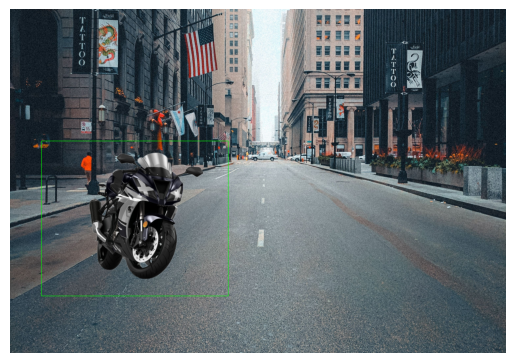

In [6]:
import cv2
import matplotlib.pyplot as plt

# Construct paths for the image and its corresponding ground truth label
image_path = "../data/train/images"
first_image_path = os.path.splitext(filename)[0] + '.jpg'
image_file = os.path.join(image_path, first_image_path)

image = cv2.imread(image_file)

if image is None:
    print("Error: Image not found.")
else:
    # Extract absolute image dimensions required for denormalizing YOLO coordinates
    height, width = image.shape[:2]
    
    label_path = os.path.join(path, filename)
    with open(label_path, 'r') as file:
        image_parameters = file.readlines()

    for parameters in image_parameters:
        values = parameters.split()

        class_id = int(values[0])
        x_center = float(values[1])
        y_center = float(values[2])
        box_width = float(values[3])
        box_height = float(values[4])

        # Denormalize relative coordinates (0.0 - 1.0) back to absolute pixel values
        x_center_pixels = x_center * width
        y_center_pixels = y_center * height
        box_width_pixels = box_width * width
        box_height_pixels = box_height * height

        # Calculate top-left (x_min, y_min) and bottom-right (x_max, y_max) corners for OpenCV
        x_min = int(x_center_pixels - (box_width_pixels / 2))
        y_min = int(y_center_pixels - (box_height_pixels / 2))
        x_max = int(x_center_pixels + (box_width_pixels / 2))
        y_max = int(y_center_pixels + (box_height_pixels / 2))

        # Draw the Ground Truth bounding box to visually verify annotation accuracy
        cv2.rectangle(
            image,
            (x_min, y_min),
            (x_max, y_max),
            (0, 255, 0),
            2
        )

    # Convert OpenCV BGR format to Matplotlib RGB for proper color rendering
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()